In [3]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")   # on remonte a la racine du projet
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from reco.data import GENRES

sns.set_theme()
os.makedirs("reports/figures", exist_ok=True)
print(os.getcwd())

/app


In [4]:
train = pd.read_csv("data/processed/train.csv")
val = pd.read_csv("data/processed/val.csv")
test = pd.read_csv("data/processed/test.csv")
items = pd.read_csv("data/processed/items.csv")
full = pd.concat([train, val, test])
print(len(train), len(val), len(test), len(full))
train.head()

80024 9988 9988 100000


,user,item,rating,ts
0,0,167,5,874965478
1,0,171,5,874965478
2,0,164,5,874965518
3,0,155,4,874965556
4,0,165,5,874965677


1    0.054
2    0.104
3    0.268
4    0.352
5    0.221
Name: rating, dtype: float64
moyenne : 3.581 | mediane : 4.0


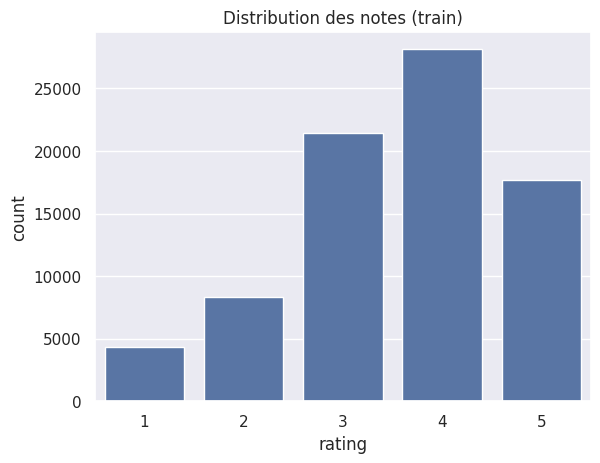

In [5]:
print(train["rating"].value_counts(normalize=True).sort_index().round(3))
print("moyenne :", round(train["rating"].mean(), 3), "| mediane :", train["rating"].median())
sns.countplot(x="rating", data=train)
plt.title("Distribution des notes (train)")
plt.savefig("reports/figures/rating_dist.png", dpi=120, bbox_inches="tight")
plt.show()

count    943.000000
mean     106.044539
std      100.931743
min       20.000000
25%       33.000000
50%       65.000000
75%      148.000000
max      737.000000
dtype: float64
min notes par user : 20


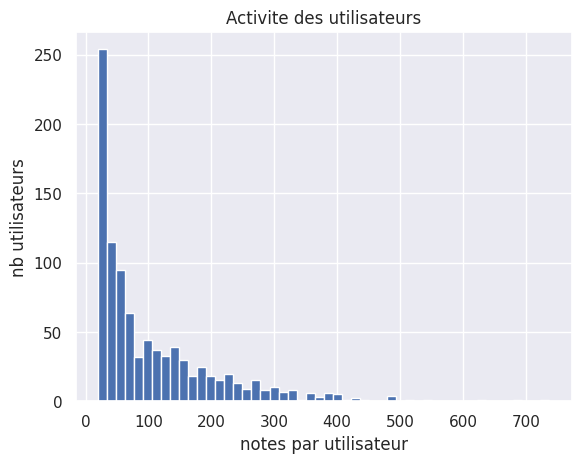

In [6]:
user_counts = full.groupby("user").size()
print(user_counts.describe())
print("min notes par user :", user_counts.min())
plt.figure()
plt.hist(user_counts, bins=50)
plt.xlabel("notes par utilisateur")
plt.ylabel("nb utilisateurs")
plt.title("Activite des utilisateurs")
plt.savefig("reports/figures/user_activity.png", dpi=120, bbox_inches="tight")
plt.show()

count    1612.000000
mean       49.642680
std        71.138852
min         1.000000
25%         5.000000
50%        20.000000
75%        64.250000
max       526.000000
dtype: float64
part des notes des 10% de films les plus notes : 0.451
films avec moins de 5 notes : 374 sur 1612
films sans note dans le train : 70


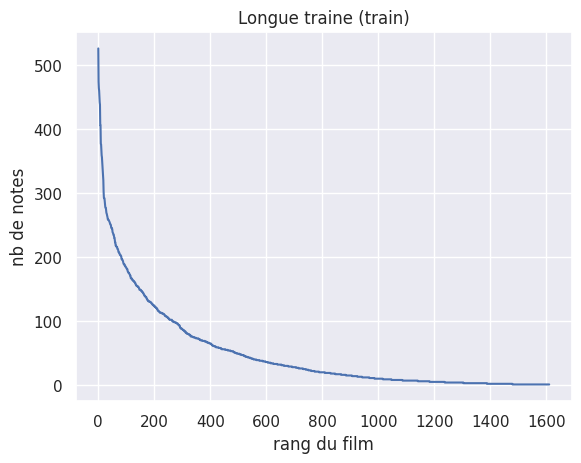

In [7]:
item_counts = train.groupby("item").size().sort_values(ascending=False)
print(item_counts.describe())
k = int(len(item_counts) * 0.1)
print("part des notes des 10% de films les plus notes :", round(item_counts.iloc[:k].sum() / item_counts.sum(), 3))
print("films avec moins de 5 notes :", (item_counts < 5).sum(), "sur", len(item_counts))
print("films sans note dans le train :", len(items) - len(item_counts))
plt.figure()
plt.plot(item_counts.values)
plt.xlabel("rang du film")
plt.ylabel("nb de notes")
plt.title("Longue traine (train)")
plt.savefig("reports/figures/long_tail.png", dpi=120, bbox_inches="tight")
plt.show()

In [8]:
n_users, n_items = full["user"].nunique(), full["item"].nunique()
print(n_users, n_items, len(full))
print("densite :", round(len(full) / (n_users * n_items) * 100, 2), "%")

943 1682 100000
densite : 6.3 %


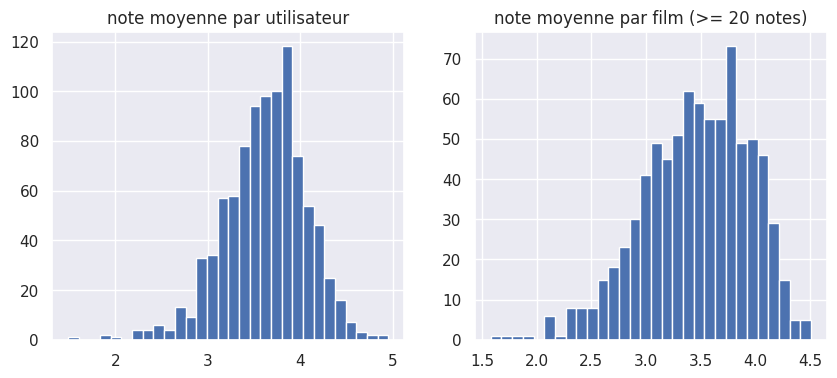

ecart-type user : 0.45 | film : 0.49


In [9]:
user_mean = train.groupby("user")["rating"].mean()
item_stats = train.groupby("item")["rating"].agg(["mean", "size"])
item_mean = item_stats[item_stats["size"] >= 20]["mean"]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist(user_mean, bins=30)
ax[0].set_title("note moyenne par utilisateur")
ax[1].hist(item_mean, bins=30)
ax[1].set_title("note moyenne par film (>= 20 notes)")
plt.savefig("reports/figures/biases.png", dpi=120, bbox_inches="tight")
plt.show()
print("ecart-type user :", round(user_mean.std(), 3), "| film :", round(item_mean.std(), 3))

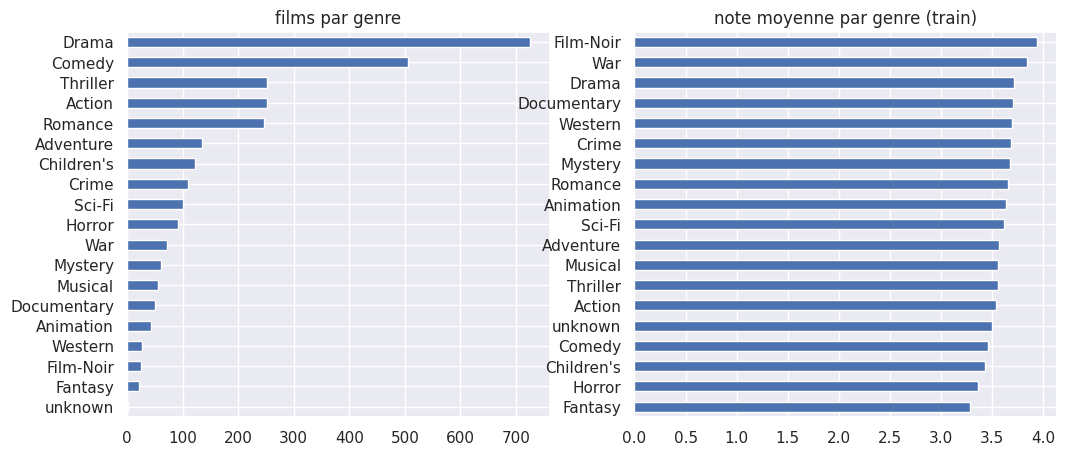

In [10]:
genre_counts = items[GENRES].sum().sort_values()
tm = train.merge(items, on="item")
genre_mean = pd.Series({g: tm.loc[tm[g] == 1, "rating"].mean() for g in GENRES}).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
genre_counts.plot.barh(ax=ax[0], title="films par genre")
genre_mean.plot.barh(ax=ax[1], title="note moyenne par genre (train)")
plt.savefig("reports/figures/genres.png", dpi=120, bbox_inches="tight")
plt.show()

1997-09-20 03:05:10 1998-04-22 23:10:38


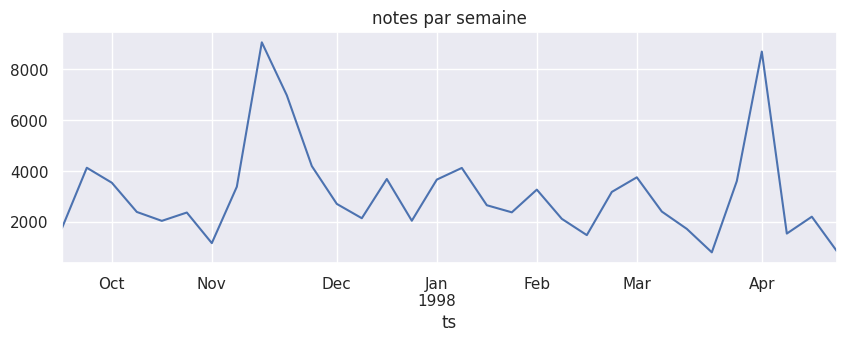

In [11]:
dates = pd.to_datetime(full["ts"], unit="s")
print(dates.min(), dates.max())
per_week = full.groupby(dates.dt.to_period("W")).size()
per_week.plot(figsize=(10, 3), title="notes par semaine")
plt.savefig("reports/figures/time.png", dpi=120, bbox_inches="tight")
plt.show()

In [15]:
seen = set(train["item"])
n_cold = (~test["item"].isin(seen)).sum()
print("notes du test sur un film absent du train :", n_cold, "sur", len(test))

notes du test sur un film absent du train : 52 sur 9988


## Conclusions pour la modelisation
- Notes concentrees sur 3-4 (62 %), moyenne 3,58 -> la "moyenne globale" est la baseline a battre.
- Densite 6,3 % -> regularisation (weight decay, dropout) et early stopping.
- Ecart-type des notes moyennes : 0,45 par user, 0,49 par film -> biais b_u et b_i dans le modele.
- Longue traine : 45,1 % des notes sur les 10 % de films les plus notes ; 374 films sur 1612 ont moins de 5 notes -> baseline "popularite" forte.
- 70 films n'ont aucune note dans le train ; 52 notes du test (0,5 %) concernent un film absent du train -> prediction par la moyenne globale.
- Utilisateurs : min 20 notes, mediane 65, max 737 -> activite tres inegale.